In [2]:
import os 
import numpy as np
import matplotlib.pyplot as plt

In [3]:
os.listdir("data/IMS")

['1st_test.rar',
 '2nd_test.rar',
 'Readme Document for IMS Bearing Data.pdf',
 '3rd_test.rar',
 '2nd_test']

In [4]:
os.listdir("data/IMS/2nd_test")[:5]

['2004.02.12.12.32.39',
 '2004.02.15.06.22.39',
 '2004.02.16.15.42.39',
 '2004.02.15.22.22.39',
 '2004.02.15.23.22.39']

In [5]:
DATA_DIR = "data/IMS/2nd_test"
files = sorted(os.listdir(DATA_DIR))
print(len(files))
print(files[:3])

984
['2004.02.12.10.32.39', '2004.02.12.10.42.39', '2004.02.12.10.52.39']


In [6]:
first = np.loadtxt(os.path.join(DATA_DIR, files[0]))
last = np.loadtxt(os.path.join(DATA_DIR, files[-1]))
print(first.shape, last.shape)

(20480, 4) (20480, 4)


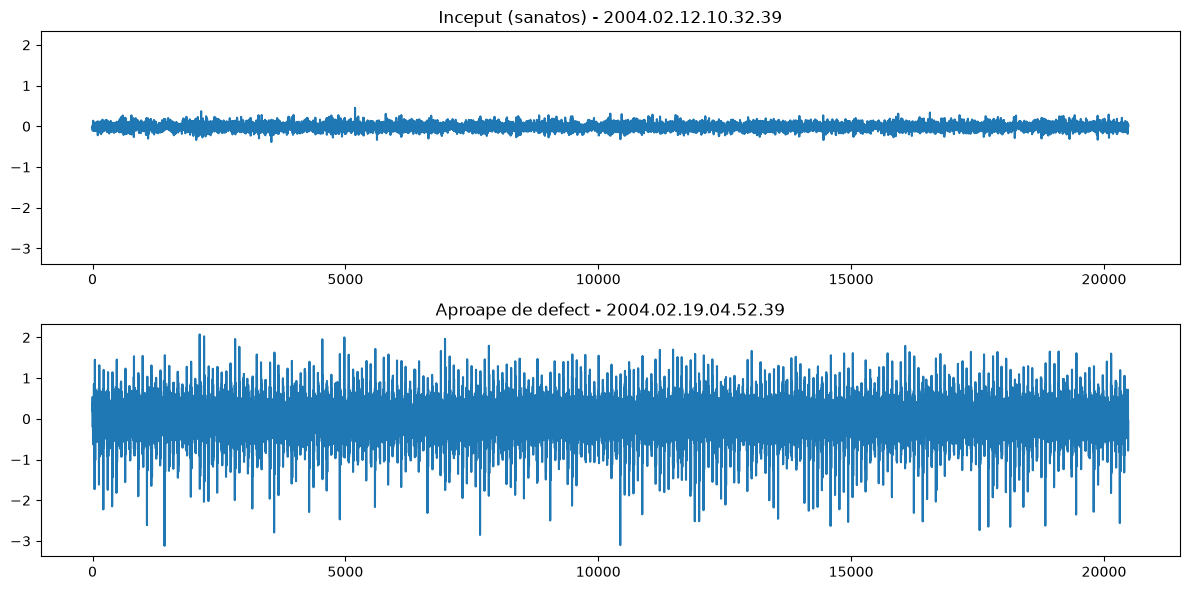

In [7]:
late = np.loadtxt(os.path.join(DATA_DIR, files[-10]))

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharey=True)
axes[0].plot(first[:, 0])
axes[0].set_title(f"Inceput (sanatos) - {files[0]}")
axes[1].plot(late[:, 0])
axes[1].set_title(f"Aproape de defect - {files[-10]}")
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/raw_signal_start_vs_end.png", dpi=150)
plt.show()

In [8]:
for i in [0, -50, -10, -2, -1]:
    data = np.loadtxt(os.path.join(DATA_DIR, files[i]))
    print(files[i], data[:, 0].std().round(3))

2004.02.12.10.32.39 0.073
2004.02.18.22.12.39 0.224
2004.02.19.04.52.39 0.448
2004.02.19.06.12.39 0.001
2004.02.19.06.22.39 0.001


In [9]:
rms = []
for f in files:
    data = np.loadtxt(os.path.join(DATA_DIR, f))
    rms.append(np.sqrt(np.mean(data**2, axis=0)))
rms = np.array(rms)
print(rms.shape)

(984, 4)


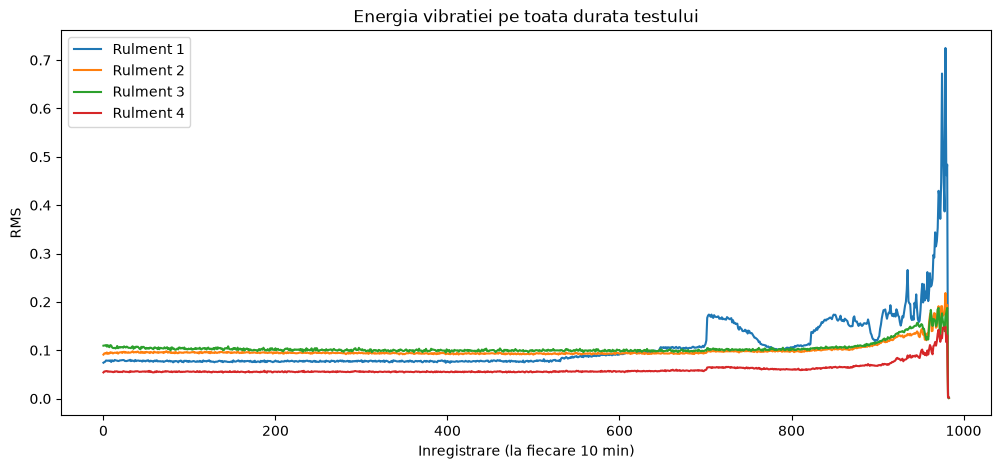

In [10]:
plt.figure(figsize=(12, 5))
for b in range(4):
    plt.plot(rms[:, b], label=f"Rulment {b+1}")
plt.xlabel("Inregistrare (la fiecare 10 min)")
plt.ylabel("RMS")
plt.title("Energia vibratiei pe toata durata testului")
plt.legend()
plt.savefig("figures/rms_over_time.png", dpi=150)
plt.show()

In [11]:
from scipy.stats import kurtosis

kurt = []
for f in files:
    data = np.loadtxt(os.path.join(DATA_DIR, f))
    kurt.append(kurtosis(data, axis=0, fisher=False))
kurt = np.array(kurt)

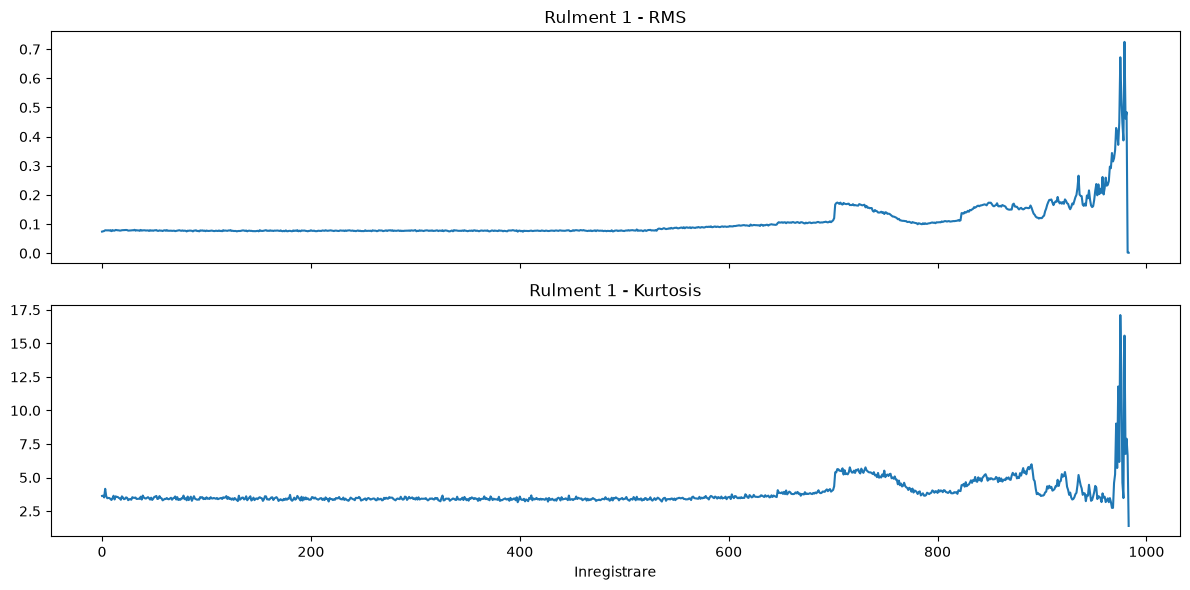

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(rms[:, 0])
axes[0].set_title("Rulment 1 - RMS")
axes[1].plot(kurt[:, 0])
axes[1].set_title("Rulment 1 - Kurtosis")
axes[1].set_xlabel("Inregistrare")
plt.tight_layout()
plt.savefig("figures/rms_vs_kurtosis_bearing1.png", dpi=150)
plt.show()

In [13]:
p2p = []
for f in files:
    data = np.loadtxt(os.path.join(DATA_DIR, f))
    p2p.append(data.max(axis=0) - data.min(axis=0))
p2p = np.array(p2p)

In [14]:
X = np.column_stack([rms[:, 0], kurt[:, 0], p2p[:, 0]])
print(X.shape)

(984, 3)


In [21]:
from sklearn.ensemble import IsolationForest

N_TRAIN = 300
model = IsolationForest(random_state=42)
model.fit(X[10:N_TRAIN])

scores = -model.score_samples(X)        # mai mare = mai anormal
threshold = np.percentile(scores[10:N_TRAIN], 99)

above = scores > threshold
K = 3   # cate inregistrari la rand (3 = 30 min)
first_alarm = None
for i in range(N_TRAIN, len(scores) - K):
    if above[i:i+K].all():
        first_alarm = i
        break
hours_before = (len(files) - first_alarm) * 10 / 60
print(f"Prima alarma: index {first_alarm}, {files[first_alarm]}")
print(f"Cu ~{hours_before:.0f} ore inainte de finalul testului")

Prima alarma: index 535, 2004.02.16.03.42.39
Cu ~75 ore inainte de finalul testului


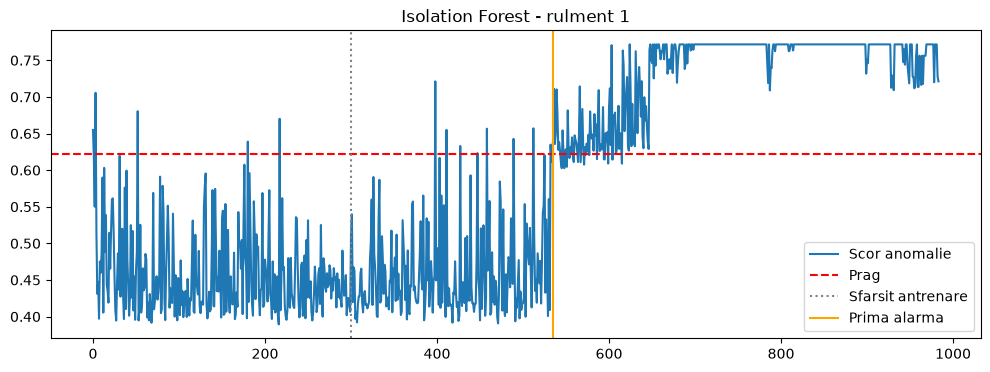

In [22]:
plt.figure(figsize=(12, 4))
plt.plot(scores, label="Scor anomalie")
plt.axhline(threshold, color="red", linestyle="--", label="Prag")
plt.axvline(N_TRAIN, color="gray", linestyle=":", label="Sfarsit antrenare")
plt.axvline(first_alarm, color="orange", label="Prima alarma")
plt.legend()
plt.title("Isolation Forest - rulment 1")
plt.savefig("figures/isolation_forest_scores.png", dpi=150)
plt.show()